# Random Forest phenotype-confidence classifier: evidence-chapter metrics and figures


**Protocol (same as `src/train_rf.py`):** 12 raw items (Q4–Q15) → k-means (k=3) phenotype labels → `RandomForestClassifier(n_estimators=200, random_state=42)` evaluated with stratified 5-fold CV (`shuffle=True`, `random_state=42`). Metrics use **out-of-fold** predictions, so every dog is predicted by a model that never saw it.



In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "cluster.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import cluster, irt   # project modules (imported before sklearn so the name 'cluster' stays ours)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, roc_curve, auc,
                             precision_recall_fscore_support, confusion_matrix)
from sklearn.calibration import calibration_curve
from sklearn.preprocessing import label_binarize

warnings.filterwarnings("ignore")
FIG = ROOT / "notebooks" / "figures"; TAB = ROOT / "notebooks" / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
                     "font.family": "serif", "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"Generalised": "#c0392b", "Mild": "#2e86c1", "Noise-specific": "#d68910"}
SEED = 42

## 1. Data, phenotype labels and cross-validated predictions

In [2]:
responses = pd.read_csv(ROOT / "data" / "raw" / "responses.csv")
labels, profiles = cluster.fit_clusters(responses)
y = labels.map(cluster.label_clusters_by_profile(profiles)).rename("phenotype")
X = responses[irt.ITEMS_ALL]
classes = sorted(y.unique())

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=200, random_state=SEED)
proba = cross_val_predict(rf, X, y, cv=cv, method="predict_proba")   # out-of-fold probabilities
pred = np.array(classes)[proba.argmax(axis=1)]
conf = proba.max(axis=1)                                             # confidence = top-class probability
print("n =", len(y)); print(y.value_counts())

silhouette by k: {2: np.float64(0.1323), 3: np.float64(0.1237), 4: np.float64(0.1233), 5: np.float64(0.1218), 6: np.float64(0.1223)}
NOTE: silhouette prefers k=2 (0.1323) over k=3 (0.1237); using k=3 anyway because rules.py's fixed 9-cell matrix requires exactly three phenotypes (architecture constraint, not a statistical free choice).


n = 163
phenotype
Mild              61
Noise-specific    59
Generalised       43
Name: count, dtype: int64


## 2. Table 10 — Random Forest classifier results

In [3]:
y_bin = label_binarize(y, classes=classes)
table10 = pd.DataFrame({
    "Metric": ["Cohort size", "Cross validation schema", "Accuracy", "Macro F1", "Macro ROC-AUC"],
    "Value": [len(y), "Stratified 5-fold, random_state = 42",
              f"{accuracy_score(y, pred):.4f}",
              f"{f1_score(y, pred, average='macro'):.4f}",
              f"{roc_auc_score(y_bin, proba, average='macro', multi_class='ovr'):.4f}"]})
table10.to_csv(TAB / "table10_overall.csv", index=False)
table10

,Metric,Value
0,Cohort size,163
1,Cross validation schema,"Stratified 5-fold, random_state = 42"
2,Accuracy,0.9018
3,Macro F1,0.9005
4,Macro ROC-AUC,0.9828


## 3. Table 11 — Per-class performance

In [4]:
p, r, f, s = precision_recall_fscore_support(y, pred, labels=classes)
table11 = pd.DataFrame({"Phenotype": classes, "Precision": p.round(4), "Recall": r.round(4),
                        "F1": f.round(4), "Support": s})
table11.to_csv(TAB / "table11_per_class.csv", index=False)
table11

,Phenotype,Precision,Recall,F1,Support
0,Generalised,0.9250,0.8605,0.8916,43
1,Mild,0.8788,0.9508,0.9134,61
2,Noise-specific,0.9123,0.8814,0.8966,59


## 4. Confusion matrix (rows = true label, columns = predicted label)

In [5]:
cm = confusion_matrix(y, pred, labels=classes)
cm_df = pd.DataFrame(cm, index=[f"True {c}" for c in classes], columns=[f"Pred {c}" for c in classes])
cm_df.to_csv(TAB / "confusion_matrix.csv")
cm_df

,Pred Generalised,Pred Mild,Pred Noise-specific
True Generalised,37,4,2
True Mild,0,58,3
True Noise-specific,3,4,52


## Figures

### Figure A — Confusion matrix (counts and row-normalised)

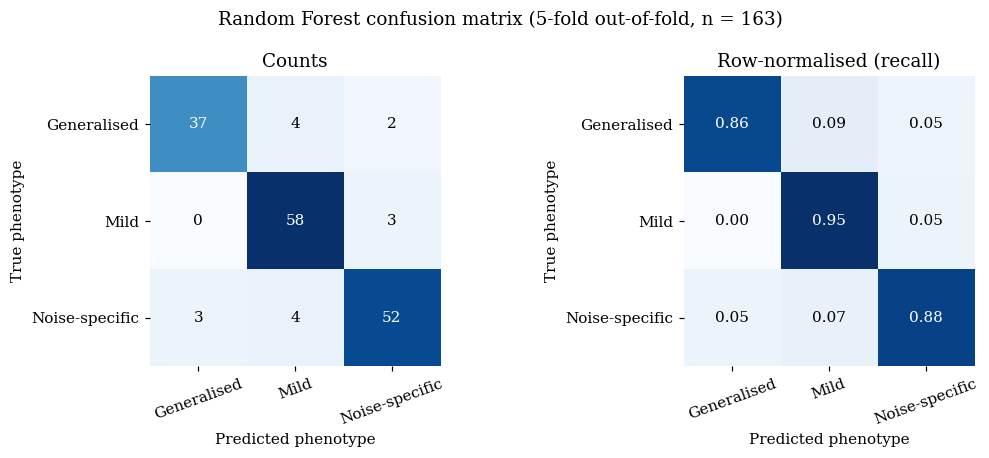

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, data, title, fmt in [(axes[0], cm, "Counts", "d"),
                             (axes[1], cm / cm.sum(axis=1, keepdims=True), "Row-normalised (recall)", ".2f")]:
    im = ax.imshow(data, cmap="Blues", vmin=0)
    ax.set_xticks(range(3), classes, rotation=20); ax.set_yticks(range(3), classes)
    ax.set_xlabel("Predicted phenotype"); ax.set_ylabel("True phenotype"); ax.set_title(title)
    for i in range(3):
        for j in range(3):
            v = data[i, j]
            ax.text(j, i, format(v, fmt), ha="center", va="center",
                    color="white" if v > data.max() * 0.6 else "black")
    ax.spines[:].set_visible(False)
fig.suptitle("Random Forest confusion matrix (5-fold out-of-fold, n = 163)")
fig.tight_layout(); fig.savefig(FIG / "fig_confusion_matrix.png"); plt.show()

### Figure B — Per-class precision, recall and F1

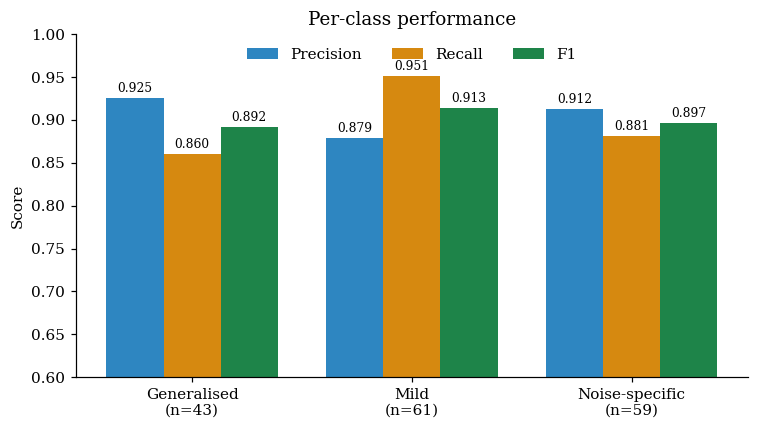

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
w = 0.26; x = np.arange(3)
for k, (name, vals, col) in enumerate([("Precision", p, "#2e86c1"), ("Recall", r, "#d68910"), ("F1", f, "#1e8449")]):
    bars = ax.bar(x + (k - 1) * w, vals, w, label=name, color=col)
    ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
ax.set_xticks(x, [f"{c}\n(n={n})" for c, n in zip(classes, s)])
ax.set_ylim(0.6, 1.0); ax.set_ylabel("Score"); ax.set_title("Per-class performance"); ax.legend(frameon=False, ncol=3, loc="upper center")
fig.tight_layout(); fig.savefig(FIG / "fig_per_class_metrics.png"); plt.show()

### Figure C — One-vs-rest ROC curves

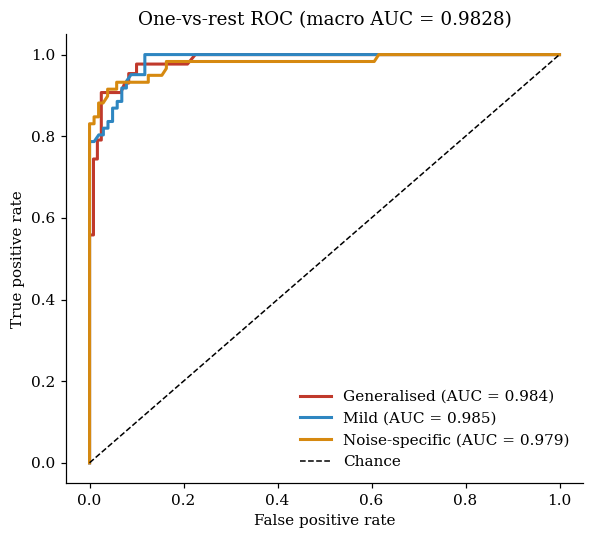

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 5))
aucs = []
for i, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_bin[:, i], proba[:, i]); a = auc(fpr, tpr); aucs.append(a)
    ax.plot(fpr, tpr, color=COLORS[c], lw=2, label=f"{c} (AUC = {a:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title(f"One-vs-rest ROC (macro AUC = {np.mean(aucs):.4f})"); ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "fig_roc_curves.png"); plt.show()
pd.DataFrame({"Phenotype": classes, "ROC-AUC": np.round(aucs, 4)}).to_csv(TAB / "per_class_auc.csv", index=False)

### Figure D — Confidence distribution for correct vs incorrect predictions
The RF probability is what the pipeline uses as the confidence value, so this shows that it separates reliable from unreliable assignments.

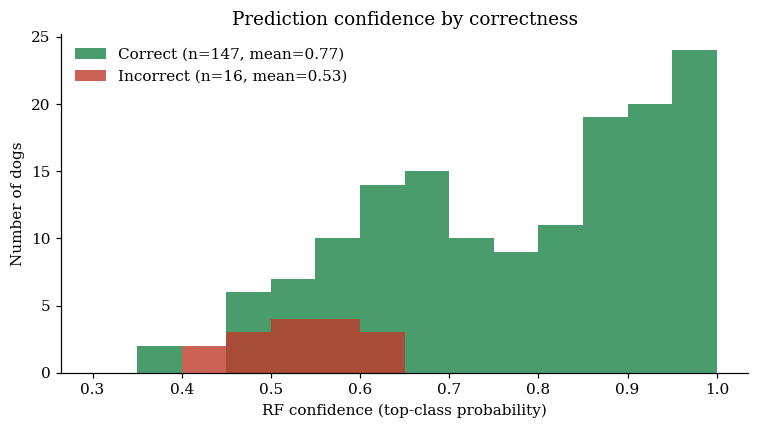

In [9]:
correct = pred == y.to_numpy()
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(0.3, 1.0, 15)
ax.hist(conf[correct], bins, alpha=.8, color="#1e8449", label=f"Correct (n={correct.sum()}, mean={conf[correct].mean():.2f})")
ax.hist(conf[~correct], bins, alpha=.8, color="#c0392b", label=f"Incorrect (n={(~correct).sum()}, mean={conf[~correct].mean():.2f})")
ax.set_xlabel("RF confidence (top-class probability)"); ax.set_ylabel("Number of dogs")
ax.set_title("Prediction confidence by correctness"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "fig_confidence_distribution.png"); plt.show()

### Figure E — Reliability (calibration) diagram

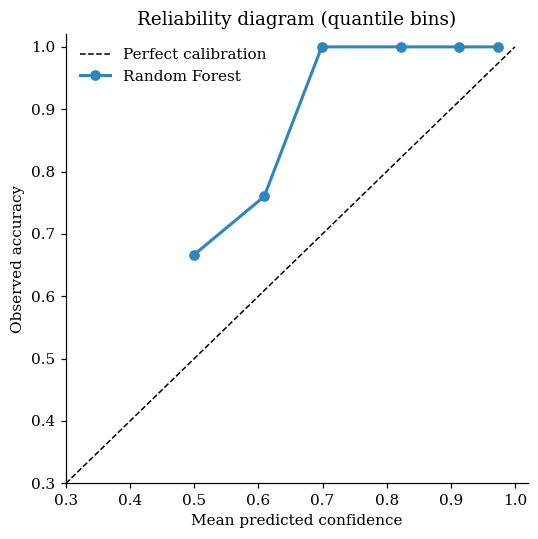

In [10]:
frac, mean_conf = calibration_curve(correct.astype(int), conf, n_bins=6, strategy="quantile")
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
ax.plot(mean_conf, frac, "o-", color="#2e86c1", lw=2, label="Random Forest")
ax.set_xlabel("Mean predicted confidence"); ax.set_ylabel("Observed accuracy")
ax.set_title("Reliability diagram (quantile bins)"); ax.legend(frameon=False); ax.set_xlim(0.3, 1.02); ax.set_ylim(0.3, 1.02)
fig.tight_layout(); fig.savefig(FIG / "fig_calibration.png"); plt.show()

### Figure F — Accuracy vs confidence threshold (coverage trade-off)

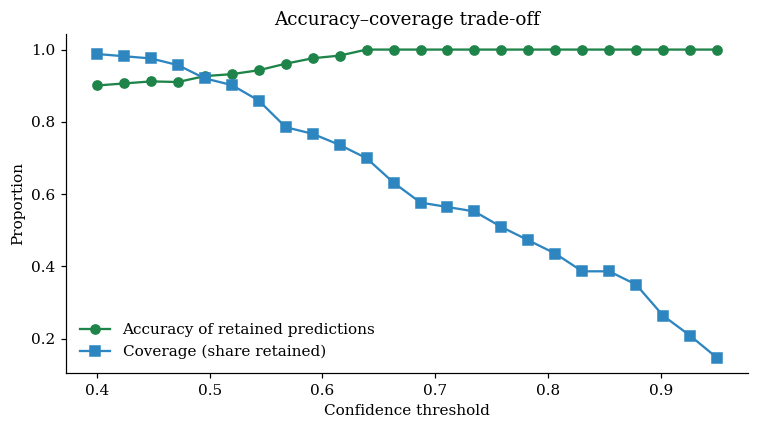

In [11]:
thr = np.linspace(0.4, 0.95, 24)
acc_t = [correct[conf >= t].mean() if (conf >= t).any() else np.nan for t in thr]
cov_t = [(conf >= t).mean() for t in thr]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thr, acc_t, "o-", color="#1e8449", label="Accuracy of retained predictions")
ax.plot(thr, cov_t, "s-", color="#2e86c1", label="Coverage (share retained)")
ax.set_xlabel("Confidence threshold"); ax.set_ylabel("Proportion"); ax.set_title("Accuracy–coverage trade-off")
ax.legend(frameon=False, loc="lower left")
fig.tight_layout(); fig.savefig(FIG / "fig_accuracy_coverage.png"); plt.show()

### Figure G — Feature importance (which items drive the phenotype)

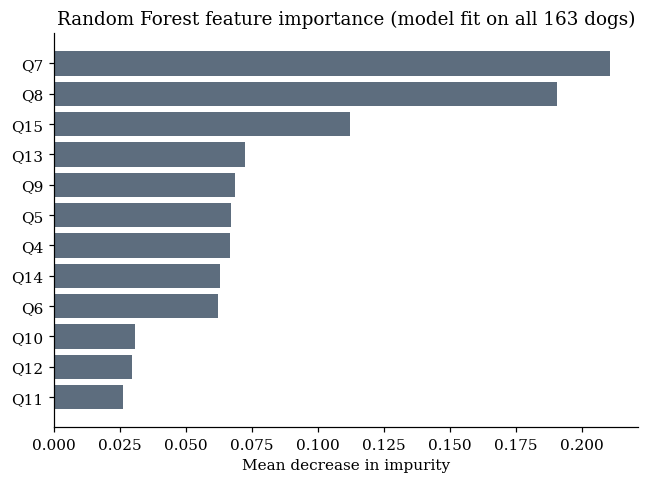

In [12]:
rf_full = RandomForestClassifier(n_estimators=200, random_state=SEED).fit(X, y)
imp = pd.Series(rf_full.feature_importances_, index=irt.ITEMS_ALL).sort_values()
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.barh(imp.index, imp.values, color="#5d6d7e"); ax.set_xlabel("Mean decrease in impurity")
ax.set_title("Random Forest feature importance (model fit on all 163 dogs)")
fig.tight_layout(); fig.savefig(FIG / "fig_feature_importance.png"); plt.show()

### Figure H — Phenotype item profiles (what each class looks like)

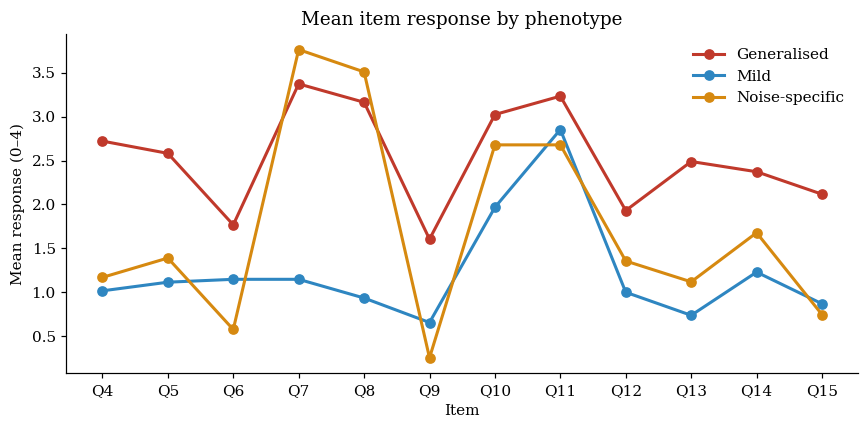

In [13]:
prof = X.groupby(y).mean().loc[classes]
fig, ax = plt.subplots(figsize=(8, 4))
for c in classes:
    ax.plot(prof.columns, prof.loc[c], "o-", lw=2, color=COLORS[c], label=c)
ax.set_xlabel("Item"); ax.set_ylabel("Mean response (0–4)"); ax.set_title("Mean item response by phenotype")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "fig_phenotype_profiles.png"); plt.show()

In [14]:
print("Saved figures:"); [print(" ", p.name) for p in sorted(FIG.glob("*.png"))]
print("Saved tables:");  [print(" ", p.name) for p in sorted(TAB.glob("*.csv"))]

Saved figures:
  fig_accuracy_coverage.png
  fig_calibration.png
  fig_confidence_distribution.png
  fig_confusion_matrix.png
  fig_feature_importance.png
  fig_per_class_metrics.png
  fig_phenotype_profiles.png
  fig_roc_curves.png
Saved tables:
  confusion_matrix.csv
  per_class_auc.csv
  table10_overall.csv
  table11_per_class.csv


[None, None, None, None]